# AI 트렌드 정리

---

### 1. AI 에이전트

#### 1-1. 정의

- **AI 에이전트**
: 사용자가 준 목표를 이루기 위해 AI 모델이 환경과 상호작용하는 시스템
    - 추론, 계획, 도구 실행이 하나로 맞물려 작동

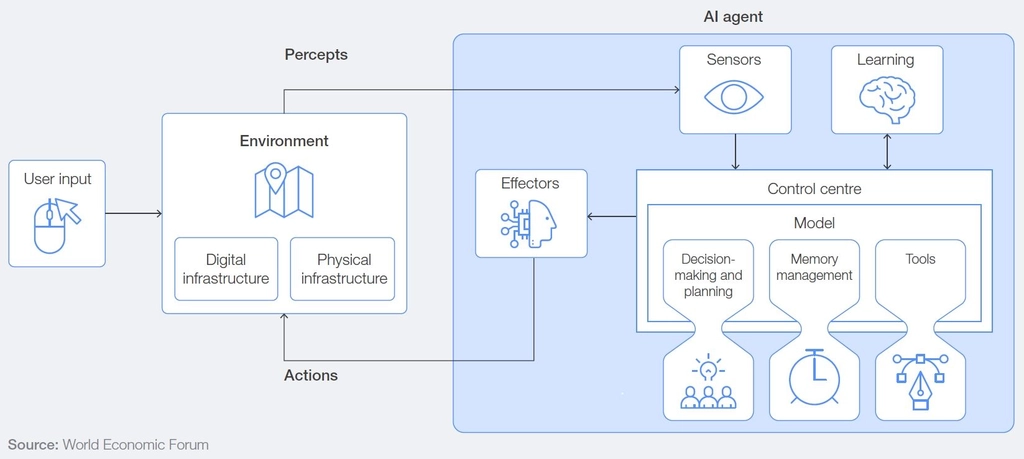

#### 1-2. 작동 방식 (ReAct)

- **생성형 AI vs 에이전틱 AI**
    - 생성형 AI: 프롬프트에 맞춰 결과를 한 번 출력하고 끝
    - 에이전틱 AI: 목표를 이룰 때까지 추론과 행동을 반복

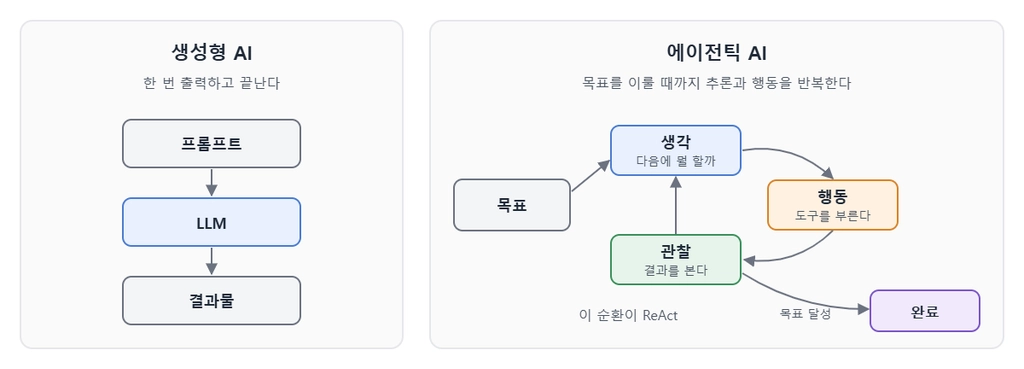

- **ReAct**
: Reasoning (추론) + Acting (행동) 
    - 생각 → 행동 → 관찰 → 다시 생각 의 순환
    - 주의: 행동 단계에서도 모델이 도구를 직접 실행하지는 않음 → 이 도구를 이 값으로 불러 달라는 요청만 만들고, 실제 실행은 앱 담당

#### 1-3. 다중 에이전트 (MAS)

- **MAS (Multi Agent System)**
: 여러 에이전트가 역할을 나눠 함께 일하는 구조
    - 대표 형태 = 오케스트레이터 + 서브 에이전트
    - 오케스트레이터: 요청을 작게 쪼갬 → 담당 배정 → 결과 통합
    - 서브 에이전트: 맡은 역할만 수행 (검색봇은 검색, 검토봇은 검토)

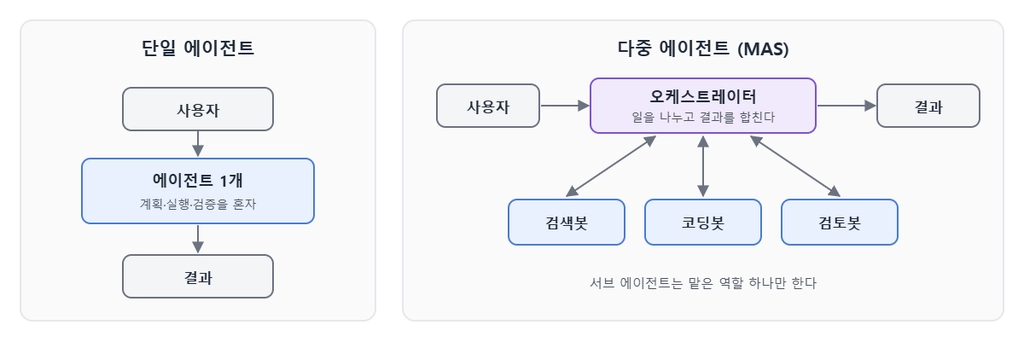

- **역할을 나누는 이유**
    - 스스로 실수 잡기 어려움
    - 여러 갈래를 동시에 조사

- **역할 나누는 경우**
    - 고정 워크플로우: 순서가 정해진 단순 작업 (매일 아침 신규 주문 정리 → 메일 발송)
    - 단일 에이전트: 도구 몇 개로 해결 가능한 작업 (배송 지연 처리)
    - 다중 에이전트: 나눠서 조사한 뒤 합칠 수 있는 큰 작업 (S&P 500 이사진 조사)

- **비용, 성능 조합**
: 모든 역할에 비싼 모델을 쓸 필요 X → 역할에 맞는 모델을 섞어 사용
    - 오케스트레이터: 고성능 모델 (Claude Opus) → 일 쪼개기와 판단이 전체 품질을 결정
    - 검색, 정리봇: 경량 모델 (Claude Haiku) → 단순 작업 위주, 빠르고 싼 모델
    - 코드 검증봇: 코드 특화 모델 → 한 가지 일 잘하는 모델이 유리 

---

### 2. MCP (Model Context Protocol)

#### 2-1. 표준이 필요한 이유

- **Function Calling**
: 모델이 구조화된 요청을 내놓는 기능
    - 실제 실행과 결과 전달은 앱 담당

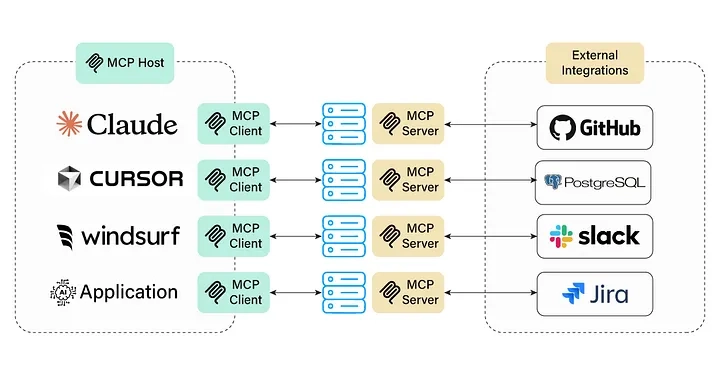

- **n×m 작업량 문제**
    - 표준 X: 앱과 도구마다 연동 코드 따로 → n×m개
    - 표준 O: 앱은 클라이언트, 도구는 서버를 한 번씩만 → n+m개

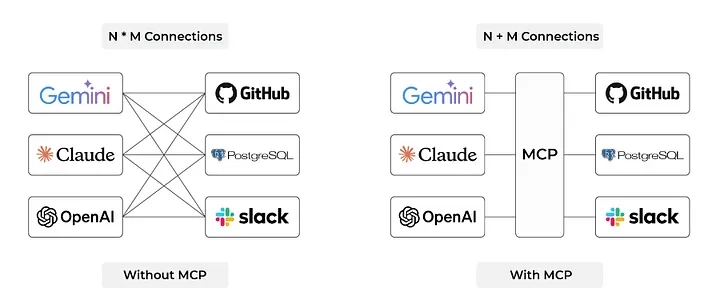

- **Function Calling vs MCP**
: 경쟁 관계 X → 대부분 둘 다 사용
    - Function Calling: 모델이 도구 호출 요청을 만드는 방식
    - MCP: 앱이 도구를 찾고, 연결하고, 호출하는 방식
    - MCP로 도구 목록 가져옴 → 모델이 Function Calling으로 선택 → 앱이 MCP로 실행

#### 2-2. MCP의 등장

- **MCP**
: LLM 앱과 외부 데이터, 도구가 통신하는 **개방형 표준 프로토콜**
    - 2024.11 Anthropic 공개 → OpenAI 등 채택 → 2025.12 리눅스 재단에 기증, 업계 공동 표준
    - 비유: AI 앱과 도구 사이의 USB-C

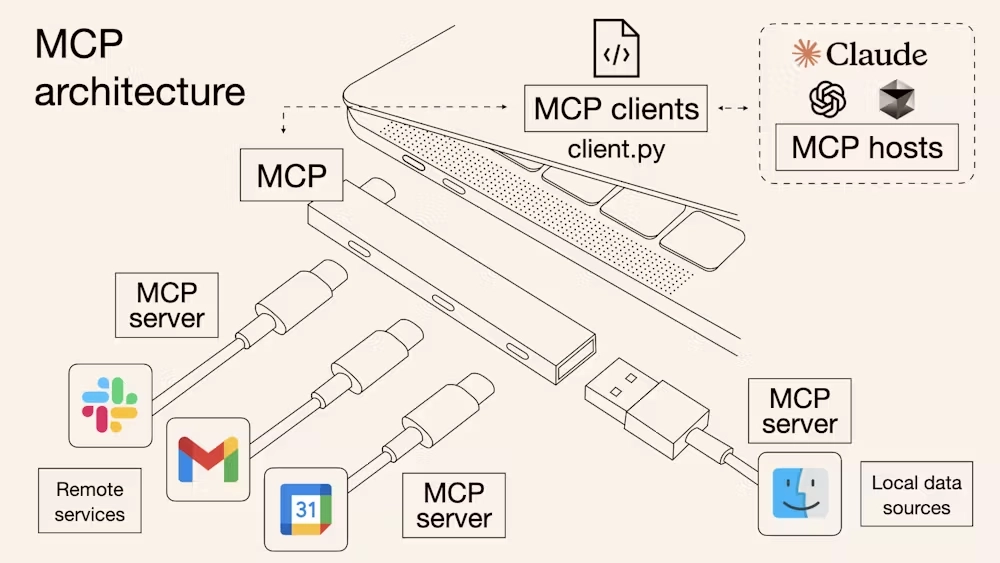

- **해결된 점**
    - n×m → n+m
    - 도구 발견 표준화: 서버가 쓸 수 있는 도구 목록 반환
    - 원격 서버 인증 통일: OAuth

- **도구 정의 구조**
    - name: 모델이 호출할 때 쓰는 이름
    - description: 모델이 읽고 언제 쓸지 판단하는 근거
    - inputSchema: 입력값의 형식

#### 2-3. MCP의 구조

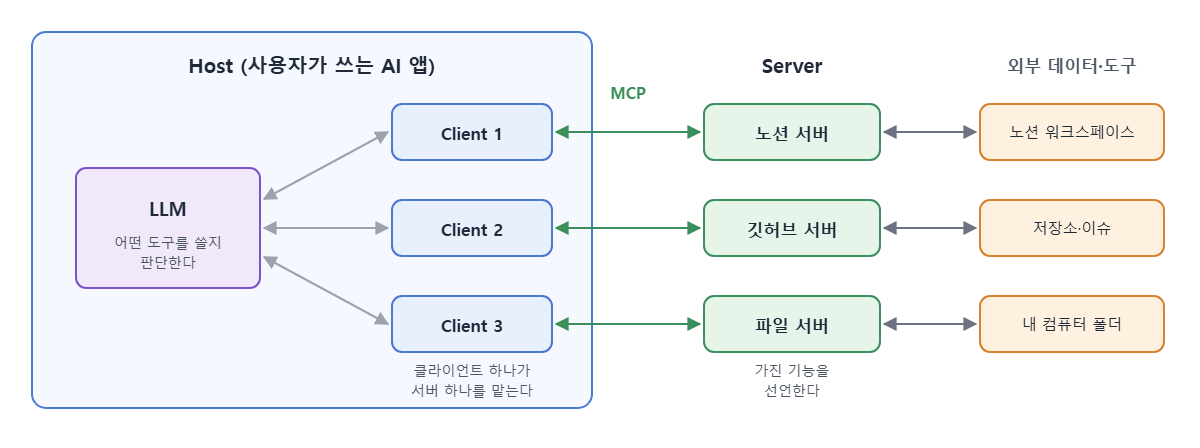

- **세 가지 역할**
    - Host: 사용자가 쓰는 AI 앱 (Claude 데스크톱, Cursor) → 클라이언트 관리, 허용할 도구 결정
    - Client: 호스트 안의 통신 담당 → 서버 하나당 하나
    - Server: 도구와 데이터를 MCP 규격으로 (노션, 깃허브) → 실제 작업 수행

- **서버의 기본 요소**
    - Tools: 실행할 수 있는 행동 (페이지 만들기, 이슈 등록)
    - Resources: 읽기 전용 데이터 (파일, 문서, DB 스키마)
    - Prompts: 재사용 가능한 템플릿 (코드 리뷰 양식, 회의록 요약 양식)

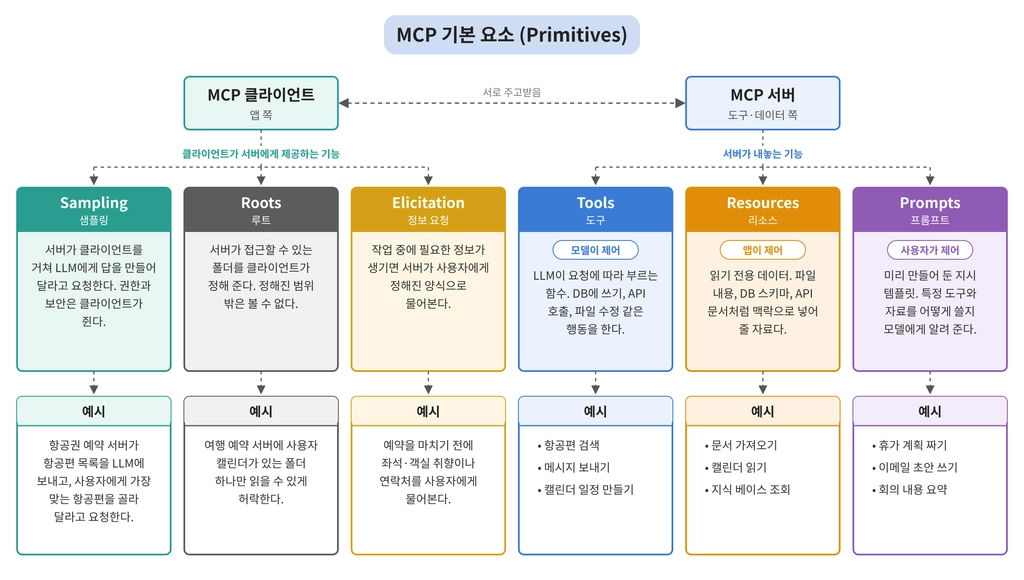

- **통신 방식**
    - 메시지 형식: JSON-RPC 2.0
    - 전송: 로컬 서버는 stdio, 원격 서버는 Streamable HTTP

#### 2-4. 작동 흐름

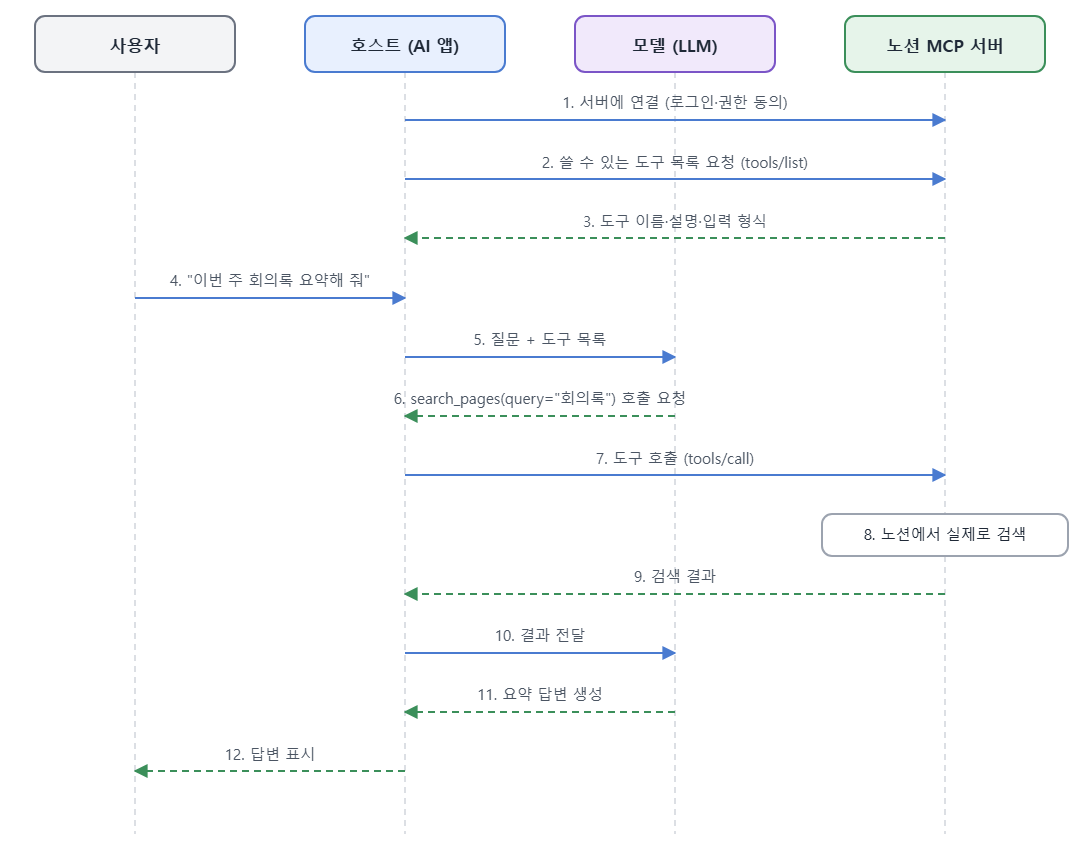

- 예) 노션 MCP가 연결된 앱에서 - "이번 주 회의록 요약해 줘"
    - 준비: 노션 로그인 (OAuth) → 도구 목록 받기 (tools/list)
    - 호스트 → 모델: 질문 + 도구 목록 전달
    - 모델 → 호스트: 검색 도구 호출 요청만
    - 호스트 → 서버: 허용 확인 → tools/call → 노션 검색
    - 결과를 모델에 전달 → 모델이 요약 답변
    - 정리: 모델 = 도구 고르기 + 답 작성 / 연결, 호출, 실행 = 호스트, 클라이언트, 서버

#### 2-5. 한계와 주의점

- **보안 책임**
: 프로토콜이 아니라 호스트에게 있음
    - MCP는 연결 방법만 정하고, 무엇을 허락할지는 정하지 않음
    - 연결이 쉬워진 만큼 공격 틈도 넓어짐

- **위험**
    - 신뢰할 수 없는 서버: 누구나 만들기 가능
    - 도구 오염 (Tool Poisoning): description 안에 모델만 읽는 지시를 숨기는 공격
    - 너무 넓은 권한: 공개 이슈에 숨긴 지시 → 비공개 저장소 내용 유출 
    - 프롬프트 주입: 도구가 가져온 내용에 지시가 섞여 들어옴 → 권한이 넓을수록 피해 증가

- **대응**
    - 공식, 검증된 서버만 연결
    - 필요한 권한만 
    - 되돌리기 어려운 호출은 사람이 승인
    - 새 서버는 도구 설명 직접 확인

---

### 3. 데이터 구조화 (그래프, 온톨로지)

#### 3-1. 구조화가 필요한 이유

- 사내 AI 도입에 흔한 방법은 RAG → 문서를 벡터 DB에 넣는 것만으로는 한계

- **Top-K 딜레마**
: 질문과 비슷한 상위 k개 청크만 가져오는데, 적절한 k를 정하기 어려움
    - k 작음 → 필요한 정보 놓침
    - k 큼 → 관련 없는 정보 섞임

- **원인**
    - 청크를 각각 따로 채점 → 청크끼리의 연결을 모름
    - 정답 청크가 질문과 안 비슷할 때가 많음 (영업팀A → 제품B → 고객C → 고객C의 불만, 마지막 청크엔 영업팀A가 없음)
    - 결국은 청크 사이의 관계를 표현하지 못함

- **해결**: 데이터 구조화 → 그래프 구조 (그래프 RAG, 그래프 DB, 팔란티어 온톨로지)

#### 3-2. 그래프와 팔란티어 온톨로지

- **그래프**
: 데이터를 노드와 엣지로 표현하는 구조
    - 노드: 사물, 존재 (봉준호, 기생충)
    - 엣지: 관계 (봉준호 —감독→ 기생충)
    - 테이블은 무엇이 있는지, 그래프는 어떻게 연결되어 있는지를 저장

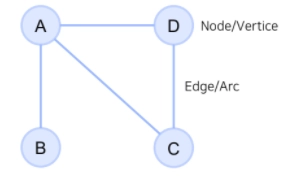

- **팔란티어 온톨로지**
: 그래프 구조를 기업 전체에 적용해 흩어진 사내 데이터를 하나의 관계망으로 묶음

- **구성요소**
    - 객체 타입, 객체, 객체 세트: 테이블 스키마, 행, 객체 모음
    - 속성, 속성값, 공유 속성: 열, 실제 값, 여러 타입이 같이 쓰는 속성
    - 링크 타입, 링크: 관계의 스키마 (구매했다), 실제 관계 (고객A가 제품B 구매)
    - 액션 타입: 읽기를 넘어 행동까지 정의 (불량 발생 시 담당자 알림) → 일반 DB와 가장 큰 차이
    - 역할: 직급, 부서별로 객체 단위까지 권한 제어 → 에이전트도 권한 범위 안에서만 움직임

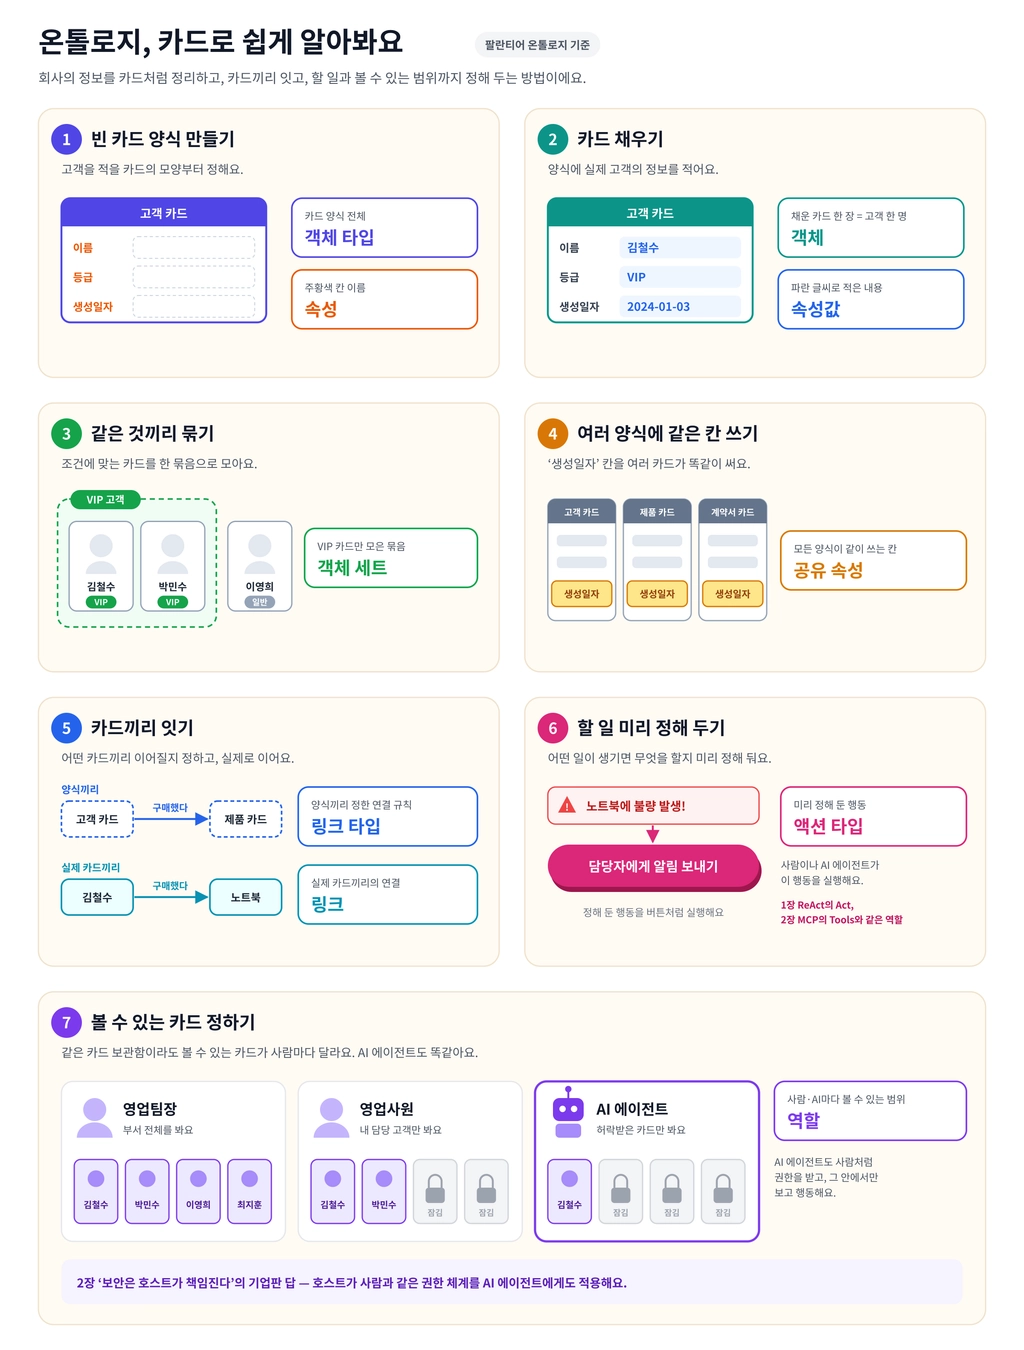

| 관계형 DB | 그래프 DB | 팔란티어 온톨로지 |
|---|---|---|
| 테이블 스키마 | - | 객체 타입 |
| 행 | 노드 | 객체 |
| 열 | - | 속성 |
| 필드 값 | - | 속성값 |
| 조인 | 엣지 | 링크 타입 |
| - | - | 액션 타입 |

#### 3-3. 실전에서 활용

- **기업**
    - Neo4j: 포춘 100대 기업 중 84곳 사용 → 사기 탐지, 추천, 소셜 관계 분석
    - Uber: 그래프 에이전트 + LLM 기반 Slack 봇 (Genie)

- **개인, 팀**
    - LightRAG: GraphRAG의 커뮤니티 요약 단계를 생략하고 비용을 줄인 가벼운 그래프 RAG
    - graphify: 폴더 안 코드, 문서를 읽어서 어떻게 연결되는지 연결 관계 그래프로 만들어 주는 도구
    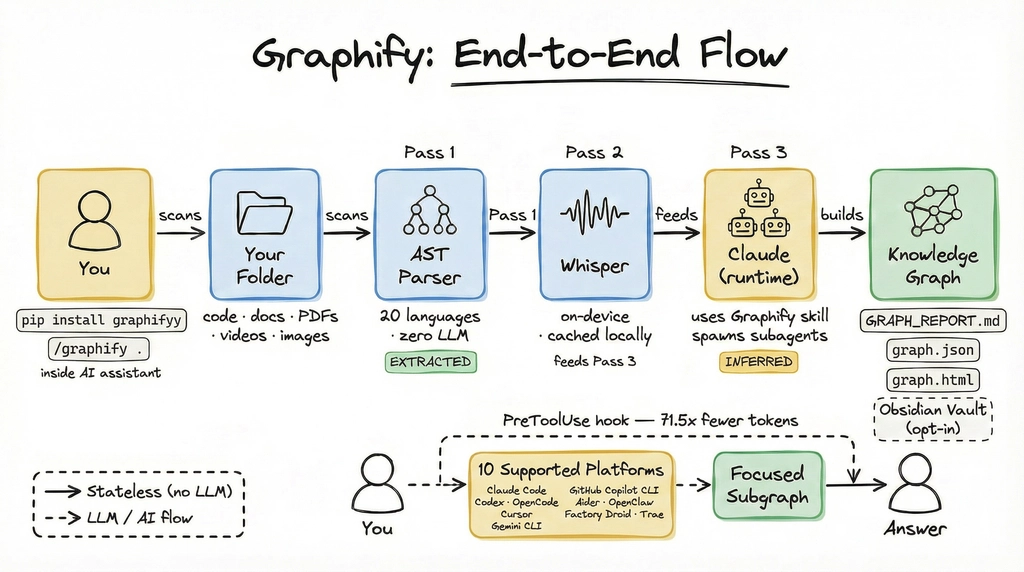
    - 팔란티어: 수백 개 데이터 소스 하나의 온톨로지로 통합
    - claude-obsidian: Claude Code + Obsidian 기반 위키형 지식 그래프

---

### 4. XAI (Explainable AI)

#### 4-1. 블랙박스 문제

- **블랙박스**
: 파라미터가 너무 많아 입력과 출력 사이 과정을 해석할 수 없음

- **필요한 이유**
    - 의료: FDA 인허가에 판단 근거 필요
    - 금융: EU AI Act, 불리한 결정의 이유 설명 의무
    - 자율주행: 사고 시 책임 소재 판단
    - 디버깅: 잘못 학습했을 때 내부를 봐야 함

#### 4-2. 기존 해결 시도

- **회귀 분석**: 계수가 바로 보임 → 복잡한 데이터에서는 성능 낮음
- **SHAP / LIME**: 입력을 바꿔 보며 입력 특성 기여도 추정 → 진짜가 아니라 그렇게 보이는 것일 수 있음
- **LLM + RAG**: LLM에게 이유를 물음 → LLM도 블랙박스

| 방법 | 설명 가능성 | 성능 | 신뢰도 |
|---|---|---|---|
| 회귀 분석 | 완전한 화이트박스 | 낮음 | 높음 |
| SHAP / LIME | 근사 설명 | 유지 | 부분적 |
| LLM + RAG | 생성된 설명 | 유지 | 낮음 |

#### 4-3. Mechanistic Interpretability

- **Mechanistic Interpretability**
: 블랙박스를 열어 모델이 어떻게 답에 도달하는지 이해하려는 연구
    - 가중치, 뉴런, 어텐션 헤드를 분석해 기능이 어디에 구현되어 있는지 역공학
    - 일반 XAI는 외부에서 관찰, Mechanistic Interpretability는 내부를 직접 해부

- **Activation Patching**
: 내부의 어느 위치가 답을 결정하는지 찾는 실험
    - 프랑스 수도 질문 (파리), 독일 수도 질문 (베를린) 준비
    - 독일 질문 처리 중 특정 위치 값을 프랑스 쪽 값으로 바꿈
    - 답이 파리로 바뀌면 → 핵심 경로

#### 4-4. 핵심 개념

- **Feature**: 모델이 입력에서 알아챈 개념 → 뉴런 하나 또는 여러 뉴런의 조합에 담김 
- **Circuit**: 여러 뉴런, 헤드가 연결되어 특정 기능을 수행하는 서브네트워크
- **Superposition**: 뉴런 하나에 여러 개념이 겹쳐 저장되는 현상
    - 개념 수가 뉴런 수보다 훨씬 많아서 겹쳐 배치
    - 해석이 어려움 → SAE (Sparse Autoencoder)로 분리

#### 4-5. 연구 사례

- **Induction Heads**: 예시를 보고 따라하는 능력이 어텐션 헤드 2개로 구현
- **Sparse Autoencoders**: Claude 3 Sonnet에서 골든 게이트 브릿지 feature를 찾아서 강제로 활성화 → 모델이 자신을 그 다리라고 소개함

#### 4-6. 왜 중요한가

- AI 안전: 배포 전에 내부 회로에 문제 있으면 수정 가능
- 아직 초기 단계지만 방향은 외부에서 추정 → 내부를 직접 열기로 이동